
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# Conditional Intensity, Compensator and Time Rescaling

**Prerequisites:** [Point processes and the Poisson process](point-processes-and-poisson-process.ipynb) · [Conditional expectation](conditional-expectation.ipynb#thm-iterated-expectations) · [Maximum likelihood estimation](maximum-likelihood-estimation.ipynb#def-log-likelihood)

A Poisson process has a fixed rate. A general point process has a rate that may depend on the past: the **conditional intensity**. This one object determines the law of the process, gives its likelihood in closed form, and turns any point process into a standard Poisson process after a change of clock. All three facts are used constantly for Hawkes processes.

## 1\. History and Conditional Intensity

Throughout, $N$ is a simple counting process on $[0, \infty)$ with event times $T_1 < T_2 < \cdots$ ([counting process](point-processes-and-poisson-process.ipynb#def-counting-process)). Its **history** (natural filtration) is
$$
\mathcal{H}_t = \sigma\big(N_s : s \le t\big),
$$
the information contained in the event times up to and including $t$. A quantity is **determined by the strict past at $t$** if it is a function of the event times in $[0, t)$ only.

The law of $N$ is determined by the conditional laws of each event time given the previous ones. We assume that these have densities: for $k \ge 1$ and $0 < t_1 < \cdots < t_{k-1}$, the law of $T_k$ given $T_1 = t_1, \dots, T_{k-1} = t_{k-1}$ has a density $f_k(t \mid t_1, \dots, t_{k-1})$ on $(t_{k-1}, \infty)$, possibly with total mass $< 1$ (the missing mass is the probability that there is no $k$-th event). Write
$$
S_k(t \mid t_1, \dots, t_{k-1}) = 1 - \int_{t_{k-1}}^t f_k(u \mid t_1, \dots, t_{k-1})\, du
$$
for the conditional survival function.

::: {#def-conditional-intensity}
## Conditional intensity
The **conditional intensity** of $N$ is the process
$$
\lambda_t = \frac{f_k(t \mid T_1, \dots, T_{k-1})}{S_k(t \mid T_1, \dots, T_{k-1})} \qquad \text{for } T_{k-1} < t \le T_k,\ k \ge 1 .
$$
On each inter-event interval it is the hazard rate of the next event time given the past. It is determined by the strict past at $t$; with continuous densities it is left-continuous, so $\lambda_{T_k}$ is the intensity *just before* the $k$-th event.
:::

::: {#prp-hazard-representation}
## Survival and density in terms of the intensity
Fix the past $T_1 = t_1, \dots, T_{k-1} = t_{k-1}$ and let $\lambda_u$, $u > t_{k-1}$, be the intensity computed as if no further event had occurred. Then
$$
S_k(t \mid \cdot) = \exp\Big(-\int_{t_{k-1}}^t \lambda_u\, du\Big), \qquad f_k(t \mid \cdot) = \lambda_t \exp\Big(-\int_{t_{k-1}}^t \lambda_u\, du\Big).
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-hazard-representation
On $\{S_k > 0\}$, $\frac{d}{dt}\big(-\log S_k(t)\big) = f_k(t)/S_k(t) = \lambda_t$ for almost every $t$, and $S_k(t_{k-1}) = 1$. Integrating gives $-\log S_k(t) = \int_{t_{k-1}}^t \lambda_u\, du$, the first formula; the second is $f_k = \lambda\, S_k$. $\blacksquare$
:::

So the conditional intensity determines every $f_k$ and hence the law of the whole process. The next result justifies the name *intensity*: $\lambda_t\,\Delta$ is the probability of an event in the next short interval, given the history.

::: {#prp-intensity-as-rate}
## Intensity as an instantaneous rate
Assume the densities $f_k$ are continuous in $t$ and that $\lambda$ is bounded on bounded intervals. Then for every $t$, almost surely,
$$
\lim_{\Delta \downarrow 0} \frac{P\big(N(t, t+\Delta] \ge 1 \mid \mathcal{H}_t\big)}{\Delta} = \lambda_{t+}, \qquad P\big(N(t, t+\Delta] \ge 2 \mid \mathcal{H}_t\big) = o(\Delta),
$$
and consequently $\lim_{\Delta\downarrow 0} E\big[N(t, t+\Delta] \mid \mathcal{H}_t\big]/\Delta = \lambda_{t+}$, where $\lambda_{t+}$ is the right limit (equal to $\lambda_t$ when $t$ is not an event time).
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-intensity-as-rate
On $\{N_t = k-1\}$ the history $\mathcal{H}_t$ consists of $T_1, \dots, T_{k-1}$ and the fact that $T_k > t$. With $\lambda_u$ computed as if no new event occurred, @prp-hazard-representation gives
$$
P\big(N(t, t+\Delta] \ge 1 \mid \mathcal{H}_t\big) = P(T_k \le t + \Delta \mid T_k > t, T_1, \dots, T_{k-1}) = 1 - \frac{S_k(t+\Delta)}{S_k(t)} = 1 - \exp\Big(-\int_t^{t+\Delta}\lambda_u\,du\Big).
$$
Since $1 - e^{-x} = x + O(x^2)$ and $\frac1\Delta\int_t^{t+\Delta}\lambda_u\,du \to \lambda_{t+}$ by continuity, the first limit follows. For two or more events: given that the $k$-th event happens at some $s \in (t, t+\Delta]$, the conditional probability of another one before $t + \Delta$ is at most $1 - e^{-C\Delta} \le C\Delta$, where $C$ bounds $\lambda$ on $[0, t+1]$. Hence $P(N(t,t+\Delta] \ge 2 \mid \mathcal{H}_t) \le (C\Delta)(C\Delta) = o(\Delta)$. The statement for the conditional expectation follows, because $E[N(t,t+\Delta] \mid \mathcal{H}_t] = P(N(t,t+\Delta] \ge 1 \mid \mathcal{H}_t) + \sum_{j\ge 2}P(N(t,t+\Delta] \ge j \mid \mathcal{H}_t)$ and the tail is bounded by the geometric series $\sum_{j \ge 2}(C\Delta)^j = o(\Delta)$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: a rate that reads the past
Informally, $P(\text{event in } [t, t + dt) \mid \text{past}) = \lambda_t\, dt$, often written $E[dN_t \mid \mathcal{H}_{t^-}] = \lambda_t\, dt$. The intensity is random because the past is random. In financial data $\lambda_t$ is, for example, the current rate of market orders given everything that has traded so far.
:::

::: {#exm-intensities}
## Three conditional intensities

1. **Inhomogeneous Poisson process** ([definition](point-processes-and-poisson-process.ipynb#def-inhomogeneous-poisson)): by independent increments, $S_k(t \mid \cdot) = P(N(t_{k-1}, t] = 0) = e^{-(\Lambda(t) - \Lambda(t_{k-1}))}$, so $\lambda_t = \lambda(t)$, a deterministic function.
2. **Renewal process**: the inter-arrival times are i.i.d. with density $g$ and survival function $\bar G$. Then $\lambda_t = h(t - T_{N_{t^-}})$ with the hazard $h = g/\bar G$: the intensity depends only on the time elapsed since the last event. If $h$ is decreasing (for example a mixture of exponentials), events cluster; if $h$ is increasing (gamma with shape $>1$), events are more regular than Poisson.
3. **Hawkes process** ([definition](hawkes-process.ipynb#def-hawkes-process)): $\lambda_t = \mu + \sum_{T_i < t}\varphi(t - T_i)$; every past event adds to the current rate.
:::

## 2\. The Compensator and the Martingale Property

::: {#def-compensator}
## Compensator
The **compensator** of $N$ is the integrated intensity
$$
\Lambda_t = \int_0^t \lambda_s\, ds .
$$
It is a continuous, nondecreasing random process, and the expected number of events "predicted by the past".
:::

::: {#lem-one-jump-martingale}
## One random time
Let $T$ be a positive random variable with density $f$, survival function $S$ and hazard $h = f/S$. Then for all $0 \le s < t$,
$$
E\Big[\mathbf{1}\{s < T \le t\} - \int_{s}^{t \wedge T} h(u)\,du \;\Big|\; T > s\Big] = 0 .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-one-jump-martingale
The first term has conditional expectation $(S(s) - S(t))/S(s)$. For the second, by Tonelli,
$$
E\Big[\int_s^{t\wedge T} h(u)\,du \;\Big|\; T > s\Big] = \int_s^t h(u)\,\frac{P(T > u)}{S(s)}\,du = \frac{1}{S(s)}\int_s^t f(u)\,du = \frac{S(s) - S(t)}{S(s)} . \qquad \blacksquare
$$
:::

::: {#thm-compensator-martingale}
## The compensated process is a martingale
If $E\,\Lambda_t < \infty$ for all $t$, then $M_t = N_t - \Lambda_t$ is a martingale with respect to $(\mathcal{H}_t)$:
$$
E\big[N(s, t] \mid \mathcal{H}_s\big] = E\Big[\int_s^t \lambda_u\, du \;\Big|\; \mathcal{H}_s\Big], \qquad s < t .
$$
:::

::: {.callout-tip collapse="true"}
## Proof sketch of @thm-compensator-martingale
Between two consecutive events the intensity is the hazard of the next event time given the past, so @lem-one-jump-martingale, applied with the conditional law of $T_k$ given $T_1, \dots, T_{k-1}$, says that the expected number of events in $(s, t] \cap (T_{k-1}, T_k]$ equals the expected integral of $\lambda$ over the same random set, given the information at its left end. Writing $N(s,t] - \int_s^t \lambda = \sum_k \big(\mathbf{1}\{s \vee T_{k-1} < T_k \le t\} - \int_{(s \vee T_{k-1}, \, t \wedge T_k]}\lambda\big)$, conditioning each term on $\mathcal{H}_{s \vee T_{k-1}}$ and using the [tower property](conditional-expectation.ipynb#thm-iterated-expectations) gives zero term by term. The interchange of sum and expectation is justified by $E\,N_t = E\,\Lambda_t < \infty$ (first for the truncated sums $\sum_{k \le K}$, then letting $K \to \infty$ by monotone convergence). A fully formal version replaces the deterministic $s$ by stopping times and uses optional stopping. $\blacksquare$
:::

The martingale property is what makes intensities computable. Its most used consequence:

::: {#cor-campbell}
## Integrating against $dN$
Let $H_s \ge 0$ be determined by the strict past at $s$ (for example $H_s = \varphi(t - s)$ for a fixed $t$, or a function of $\lambda_s$). Then
$$
E\int_0^t H_s\, dN_s = E\sum_{T_k \le t} H_{T_k} = E\int_0^t H_s\,\lambda_s\, ds .
$$
In particular $E\,N_t = \int_0^t E\,\lambda_s\, ds$.
:::

::: {.callout-tip collapse="true"}
## Proof sketch of @cor-campbell
For $H = \mathbf{1}_{(a, b]}\,\mathbf{1}_A$ with $A \in \mathcal{H}_a$, the identity is $E[\mathbf{1}_A N(a,b]] = E[\mathbf{1}_A \int_a^b\lambda]$, which follows from @thm-compensator-martingale by conditioning on $\mathcal{H}_a$. Both sides are linear in $H$ and stable under increasing limits, so the identity extends from these simple integrands to all nonnegative processes determined by the strict past (monotone class argument). $\blacksquare$
:::

::: {#thm-watanabe}
## Watanabe's characterization
A simple counting process with a continuous compensator is an inhomogeneous Poisson process if and only if its compensator $\Lambda_t$ is deterministic. (Stated without proof.)
:::

## 3\. The Likelihood of a Point Process

::: {#thm-point-process-likelihood}
## Likelihood
Let the intensity depend on a parameter $\theta$, and observe the events $0 < t_1 < \cdots < t_n \le T$ on the window $[0, T]$ (so $N_T = n$). The likelihood (joint density of the event times together with "no further event in $(t_n, T]$") is
$$
L(\theta) = \Big[\prod_{i=1}^n \lambda_{t_i}\Big]\exp\Big(-\int_0^T \lambda_t\, dt\Big), \qquad
\ell(\theta) = \log L(\theta) = \sum_{i=1}^n \log \lambda_{t_i} - \Lambda_T,
$$
where $\lambda_{t_i}$ is the left-continuous intensity at $t_i$ (computed from $t_1, \dots, t_{i-1}$ only).
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-point-process-likelihood
By the chain rule for conditional densities, the joint density of $(T_1, \dots, T_n)$ times the probability that $T_{n+1} > T$ is
$$
\Big[\prod_{k=1}^n f_k(t_k \mid t_1, \dots, t_{k-1})\Big]\, S_{n+1}(T \mid t_1, \dots, t_n).
$$
By @prp-hazard-representation, $f_k(t_k \mid \cdot) = \lambda_{t_k}\exp\big(-\int_{t_{k-1}}^{t_k}\lambda_u\,du\big)$ and $S_{n+1}(T \mid \cdot) = \exp\big(-\int_{t_n}^T \lambda_u\,du\big)$. The exponentials multiply to $\exp\big(-\int_0^T \lambda_u\,du\big)$ because the intervals $(t_{k-1}, t_k]$, $k = 1, \dots, n$, and $(t_n, T]$ partition $(0, T]$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: rewarding events, penalizing silence
The term $\sum \log\lambda_{t_i}$ rewards a model that puts high intensity where events actually occurred; the term $-\Lambda_T$ penalizes intensity spent where nothing happened. For a homogeneous Poisson process, $\ell(\lambda) = n\log\lambda - \lambda T$ is maximized at $\hat\lambda = n/T$.
:::

## 4\. The Time-Rescaling Theorem

::: {#thm-time-rescaling}
## Time rescaling
Assume $\Lambda_t \to \infty$ almost surely as $t \to \infty$. Then the rescaled times $\tau_k = \Lambda_{T_k}$ are the event times of a Poisson process with rate $1$. Equivalently, the **residual inter-arrival times**
$$
\tau_k - \tau_{k-1} = \int_{T_{k-1}}^{T_k}\lambda_u\, du, \qquad k \ge 1,
$$
are i.i.d. $\operatorname{Expo}(1)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-time-rescaling
Fix $k$ and condition on $T_1 = t_1, \dots, T_{k-1} = t_{k-1}$. Let $\lambda_u$, $u > t_{k-1}$, be the intensity computed as if no new event occurred, and $A(t) = \int_{t_{k-1}}^t \lambda_u\,du$, a continuous nondecreasing function. Because $\Lambda_\infty = \infty$ almost surely, $A(t) \to \infty$ for almost every past (otherwise, by @prp-hazard-representation, there would be a positive probability $e^{-A(\infty)}$ of no further event, and then $\Lambda$ would stay bounded). For $x > 0$ let $u_x = \inf\{t : A(t) \ge x\}$, so $A(u_x) = x$ by continuity, and $A(T_k) > x \iff T_k > u_x$ up to a null set. By @prp-hazard-representation,
$$
P\big(\tau_k - \tau_{k-1} > x \mid T_1, \dots, T_{k-1}\big) = P(T_k > u_x \mid T_1, \dots, T_{k-1}) = e^{-A(u_x)} = e^{-x}.
$$
The conditional law does not depend on the past, so $\tau_k - \tau_{k-1}$ is $\operatorname{Expo}(1)$ and independent of $(T_1, \dots, T_{k-1})$, hence of $\tau_1 - \tau_0, \dots, \tau_{k-1} - \tau_{k-2}$. By induction the gaps are i.i.d. $\operatorname{Expo}(1)$, and by [the exponential-gap construction](point-processes-and-poisson-process.ipynb#thm-poisson-from-exponential-gaps) the $\tau_k$ form a rate-$1$ Poisson process. $\blacksquare$
:::

::: {.callout-note}
## Intuition: running the clock at the speed of the intensity
Measure time not in seconds but in "expected number of events". When the intensity is high the new clock runs fast, when it is low it runs slowly. Viewed on this clock every point process looks the same: a Poisson process with rate $1$. The theorem generalizes the [time change for inhomogeneous Poisson processes](point-processes-and-poisson-process.ipynb#thm-poisson-time-change), where the clock $\Lambda$ is deterministic.
:::

::: {.callout-note}
## Algorithm: goodness of fit by time rescaling
Given data $t_1 < \cdots < t_n$ and a fitted model with intensity $\hat\lambda$:

1. compute the residual gaps $r_k = \int_{t_{k-1}}^{t_k}\hat\lambda_u\,du$ (with $t_0 = 0$);
2. compare their empirical distribution with $\operatorname{Expo}(1)$: a QQ plot, and a Kolmogorov–Smirnov test on $r_k$ (or on $1 - e^{-r_k}$, which should be uniform);
3. check independence, for example with a scatter plot of $(1 - e^{-r_k}, 1 - e^{-r_{k+1}})$ or the autocorrelation of the $r_k$.
:::

::: {.callout-warning}
## Estimated parameters
When $\hat\lambda$ uses parameters estimated from the same data, the residuals are only approximately i.i.d. exponential, and the usual KS p-values are somewhat conservative. Systematic deviations in a QQ plot (a bent tail, a gap near zero) are more informative than a single p-value.
:::

## 5\. Simulation on Mock Data

Three event streams with the same average rate $1$: a Poisson process, a regular renewal process (gamma inter-arrivals with shape $2$, hazard $h(x) = 4x/(1+2x)$), and a bursty renewal process (inter-arrival times that are $\operatorname{Expo}(4)$ with probability $0.8$ and $\operatorname{Expo}(0.25)$ with probability $0.2$, a decreasing hazard from $3.25$ down to $0.25$). The intensity of each process is plotted under its events.

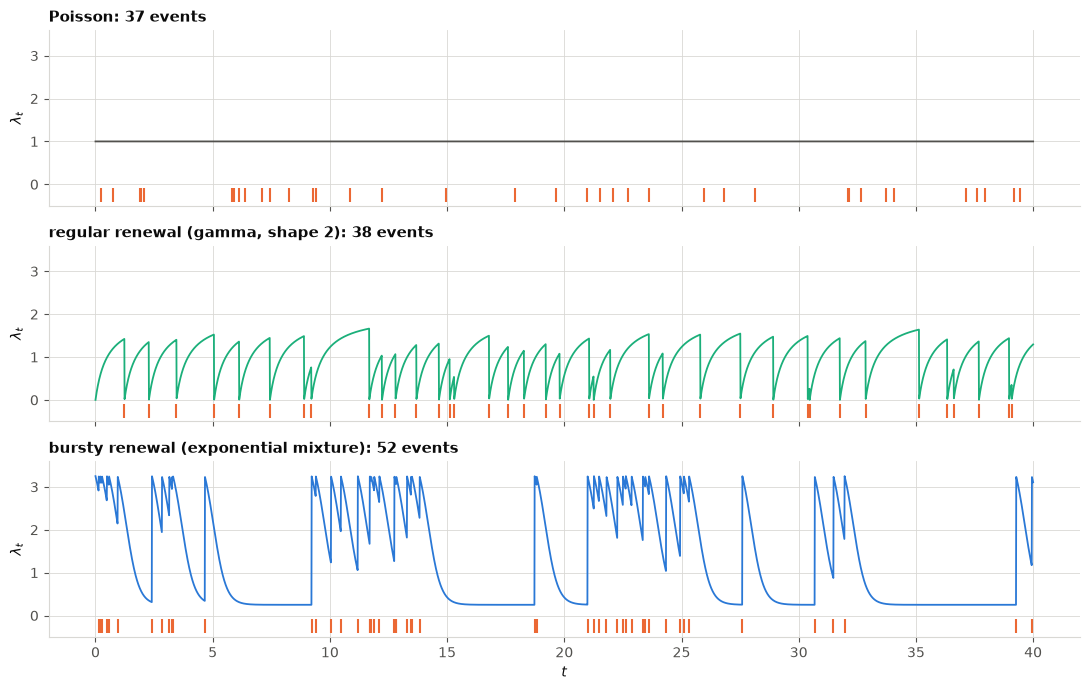

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy import stats

rng = np.random.default_rng(11)
T = 40.0

# hazards of the three inter-arrival laws (all with mean 1)
p, a, b = 0.8, 4.0, 0.25
haz = {
    "Poisson": lambda x: np.ones_like(x),
    "regular renewal (gamma, shape 2)": lambda x: 4 * x / (1 + 2 * x),
    "bursty renewal (exponential mixture)": lambda x: (p * a * np.exp(-a * x) + (1 - p) * b * np.exp(-b * x))
                                              / (p * np.exp(-a * x) + (1 - p) * np.exp(-b * x)),
}
draw = {
    "Poisson": lambda n: rng.exponential(1.0, n),
    "regular renewal (gamma, shape 2)": lambda n: rng.gamma(2.0, 0.5, n),
    "bursty renewal (exponential mixture)": lambda n: np.where(rng.random(n) < p, rng.exponential(1 / a, n), rng.exponential(1 / b, n)),
}

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, name, c in zip(axes, haz, [MUTED, AQUA, BLUE]):
    ev = np.cumsum(draw[name](200)); ev = ev[ev <= T]
    grid = np.linspace(0, T, 4000)
    last = np.r_[0, ev][np.searchsorted(ev, grid, side="left")]      # last event strictly before t
    ax.plot(grid, haz[name](grid - last), color=c, lw=1.3)
    ax.plot(ev, np.full(len(ev), -0.25), "|", color=ORANGE, ms=10, mew=1.5)
    ax.set(ylabel=r"$\lambda_t$", ylim=(-0.5, 3.6)); ax.set_title(f"{name}: {len(ev)} events", loc="left")
axes[-1].set_xlabel("$t$")
plt.tight_layout(); plt.show()


**Martingale check.** For the bursty process, $N_t - \Lambda_t$ should have mean zero at every $t$ (@thm-compensator-martingale), while a single path wanders around zero with a spread that grows like $\sqrt{t}$. The compensator of a renewal process is a sum of integrated hazards $H(x) = -\log \bar G(x)$ over the completed gaps plus the current one.

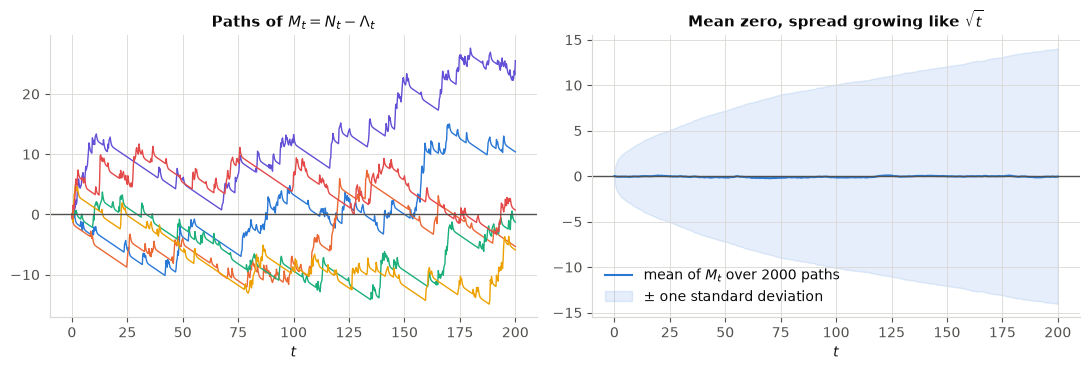

max |mean M_t| over the grid: 0.241   (std at t = 200: 14.07)


In [2]:

Gbar = lambda x: p * np.exp(-a * x) + (1 - p) * np.exp(-b * x)
H = lambda x: -np.log(Gbar(x))                                   # integrated hazard

def compensator_path(ev, grid):
    idx = np.searchsorted(ev, grid, side="right")                # N_t
    last = np.r_[0, ev][idx]
    done = np.r_[0, np.cumsum(H(np.diff(np.r_[0, ev])))]          # integrated hazard over completed gaps
    return idx, done[idx] + H(grid - last)

grid = np.linspace(0, 200, 801)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
M_all = []
for r in range(2000):
    ev = np.cumsum(draw["bursty renewal (exponential mixture)"](600)); ev = ev[ev <= 200]
    Nt, Lt = compensator_path(ev, grid)
    M_all.append(Nt - Lt)
    if r < 6:
        ax[0].plot(grid, Nt - Lt, lw=1, color=[BLUE, ORANGE, AQUA, VIOLET, YELLOW, RED][r])
M_all = np.array(M_all)
ax[0].axhline(0, color=MUTED, lw=1); ax[0].set(title=r"Paths of $M_t = N_t - \Lambda_t$", xlabel="$t$")
ax[1].plot(grid, M_all.mean(0), color=BLUE, lw=1.5, label=r"mean of $M_t$ over 2000 paths")
ax[1].fill_between(grid, -M_all.std(0), M_all.std(0), color=BLUE, alpha=0.12, label="± one standard deviation")
ax[1].axhline(0, color=MUTED, lw=1); ax[1].set(title="Mean zero, spread growing like $\\sqrt{t}$", xlabel="$t$"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()
print(f"max |mean M_t| over the grid: {np.abs(M_all.mean(0)).max():.3f}   (std at t = 200: {M_all.std(0)[-1]:.2f})")


**Time rescaling as a model check.** We observe a long bursty path and fit two models: a homogeneous Poisson process ($\hat\lambda = n/T$) and the correct renewal model. Only the correct model produces residual gaps that look $\operatorname{Expo}(1)$.

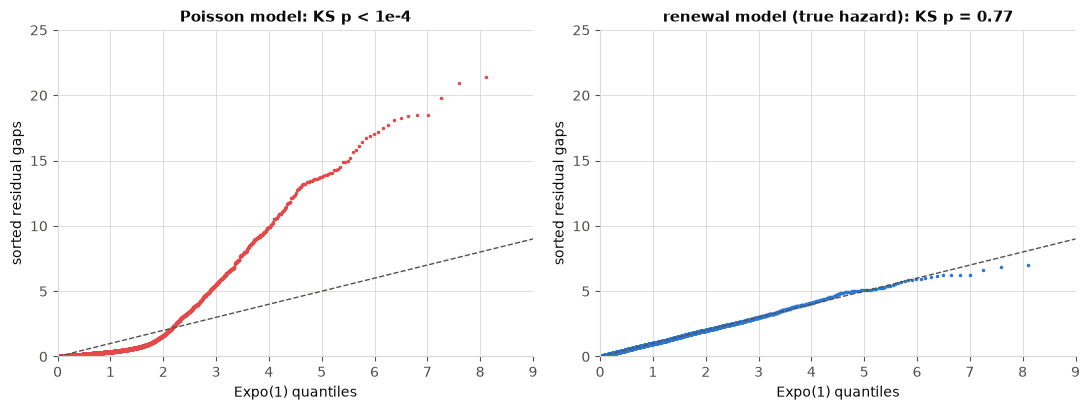

In [3]:

ev = np.cumsum(draw["bursty renewal (exponential mixture)"](6000)); ev = ev[ev <= 5000]
gaps = np.diff(np.r_[0, ev])
res = {"Poisson model": gaps * len(ev) / 5000, "renewal model (true hazard)": H(gaps)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
q = (np.arange(1, len(ev) + 1) - 0.5) / len(ev)
for axi, (name, r), c in zip(ax, res.items(), [RED, BLUE]):
    axi.plot(-np.log(1 - q), np.sort(r), ".", ms=3, color=c)
    axi.plot([0, 9], [0, 9], color=MUTED, lw=1, ls="--")
    pval = stats.kstest(r, "expon").pvalue
    axi.set(title=f"{name}: KS p = {pval:.2g}" if pval > 1e-4 else f"{name}: KS p < 1e-4", xlabel="Expo(1) quantiles", ylabel="sorted residual gaps", xlim=(0, 9), ylim=(0, 25))
plt.tight_layout(); plt.show()